#  1.Downloading GTSRB dataset, 2. preprocessing, 3. CNN model train and test for traffic sign Recognition

In [ ]:
pip install kagglehub

The German Traffic Sign Recognition Benchmark (GTSRB) dataset contains various CSV files. A common file to explore metadata is `Meta.csv`. I will attempt to load this file.

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "Meta.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign",
  file_path,
 )

print("First 5 records:", df.head())

100%|██████████| 1.01k/1.01k [00:00<00:00, 2.14MB/s]

First 5 records:           Path  ClassId  ShapeId  ColorId SignId
0  Meta/27.png       27        0        0   1.32
1   Meta/0.png        0        1        0   3.29
2   Meta/1.png        1        1        0   3.29
3  Meta/10.png       10        1        0   3.27
4  Meta/11.png       11        0        0   1.22


For a traffic sign dataset like GTSRB, the training and testing data are typically found in `Train.csv` and `Test.csv`. These files usually contain image paths and their corresponding class IDs (labels).

In [ ]:
# Load the training dataset
train_df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign",
  "Train.csv",
)

print("First 5 records of Train.csv:")
display(train_df.head())

# Load the testing dataset
test_df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign",
  "Test.csv",
)

print("\nFirst 5 records of Test.csv:")
display(test_df.head())

100%|██████████| 304k/304k [00:00<00:00, 849kB/s]

Extracting zip of Train.csv...
First 5 records of Train.csv:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


100%|██████████| 418k/418k [00:00<00:00, 958kB/s]


First 5 records of Test.csv:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


## Exploratory Data Analysis (EDA) on Training Set

In [ ]:
print("Train DataFrame Info:")
train_df.info()

print("\nTrain DataFrame Description:")
display(train_df.describe())

Train DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39209 entries, 0 to 39208
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Width    39209 non-null  int64 
 1   Height   39209 non-null  int64 
 2   Roi.X1   39209 non-null  int64 
 3   Roi.Y1   39209 non-null  int64 
 4   Roi.X2   39209 non-null  int64 
 5   Roi.Y2   39209 non-null  int64 
 6   ClassId  39209 non-null  int64 
 7   Path     39209 non-null  object
dtypes: int64(7), object(1)
memory usage: 2.4+ MB

Train DataFrame Description:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId
count,39209.000000,39209.000000,39209.000000,39209.000000,39209.000000,39209.000000,39209.000000
mean,50.835880,50.328930,5.999515,5.962381,45.197302,44.728379,15.788390
std,24.306933,23.115423,1.475493,1.385440,23.060157,21.971145,12.013238
min,25.000000,25.000000,0.000000,5.000000,20.000000,20.000000,0.000000
25%,35.000000,35.000000,5.000000,5.000000,29.000000,30.000000,5.000000
50%,43.000000,43.000000,6.000000,6.000000,38.000000,38.000000,12.000000
75%,58.000000,58.000000,6.000000,6.000000,53.000000,52.000000,25.000000
max,243.000000,225.000000,20.000000,20.000000,223.000000,205.000000,42.000000


### Class Distribution

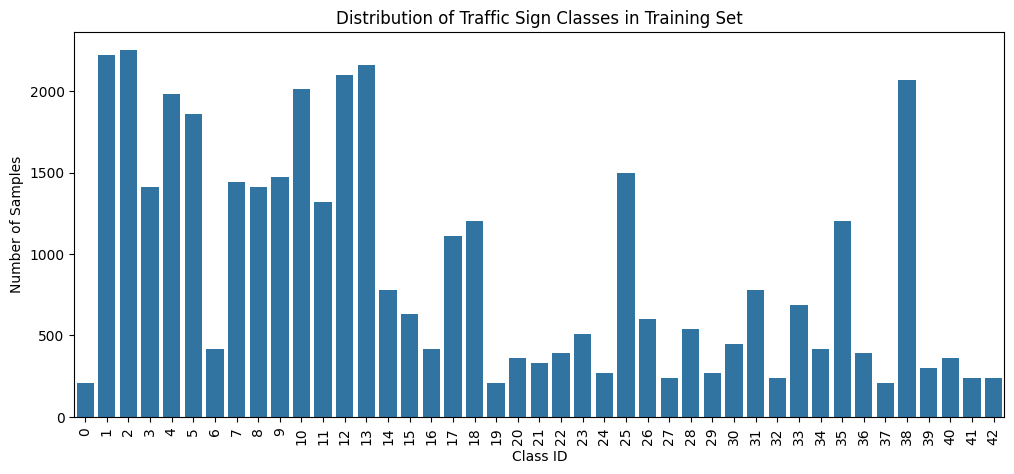

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))
sns.countplot(x='ClassId', data=train_df)
plt.title('Distribution of Traffic Sign Classes in Training Set')
plt.xlabel('Class ID')
plt.ylabel('Number of Samples')
plt.xticks(rotation=90)
plt.show()

## Preparing Datasets for Model Training

Since `train_df` and `test_df` only contain image paths, we need to download the actual image files from the Kaggle dataset. We'll then load these images, resize them to a consistent dimension (e.g., 30x30 pixels, common for GTSRB), and normalize their pixel values. We will also prepare the labels for model input.

In [ ]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

# Download the dataset to get access to the image files
print("Downloading the dataset...")
dataset_path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print(f"Dataset downloaded to: {dataset_path}")

100%|██████████| 612M/612M [00:18<00:00, 35.1MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1


### Image Loading and Preprocessing Function

In [ ]:
# Define the target image size
IMG_WIDTH = 32
IMG_HEIGHT = 32

def load_and_preprocess_image(image_path_relative, base_dataset_path):
    # Construct the full path to the image file
    full_image_path = os.path.join(base_dataset_path, image_path_relative)

    # Check if the file exists
    if not os.path.exists(full_image_path):
        # Try a common alternative path if the direct one fails (e.g., if 'Train/' is part of image_path_relative already)
        full_image_path_alt = os.path.join(base_dataset_path, 'GTSRB', 'Final_Training', image_path_relative)
        if not os.path.exists(full_image_path_alt):
            full_image_path_alt2 = os.path.join(base_dataset_path, 'gtsrb-german-traffic-sign', image_path_relative)
            if not os.path.exists(full_image_path_alt2):
                print(f"Warning: Image not found at {full_image_path} or {full_image_path_alt} or {full_image_path_alt2}")
                return None
            else:
                full_image_path = full_image_path_alt2
        else:
            full_image_path = full_image_path_alt

    # Load the image using OpenCV
    img = cv2.imread(full_image_path)

    # Check if image loading was successful
    if img is None:
        print(f"Warning: Could not load image: {full_image_path}")
        return None

    # Resize the image
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT))

    # Normalize pixel values (0-255 to 0-1)
    img = img / 255.0

    return img

### Load and Preprocess Training and Testing Images

In [ ]:
# Load and preprocess training images and labels
import tqdm
X_train = []
y_train = []

print("Processing training images...")
for idx, row in tqdm.tqdm(train_df.iterrows(), total=len(train_df)):
    img = load_and_preprocess_image(row['Path'], dataset_path)
    if img is not None:
        X_train.append(img)
        y_train.append(row['ClassId'])

X_train = np.array(X_train)
y_train = np.array(y_train)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")

# Load and preprocess testing images and labels
X_test = []
y_test = []

print("Processing testing images...")
for idx, row in tqdm.tqdm(test_df.iterrows(), total=len(test_df)):
    img = load_and_preprocess_image(row['Path'], dataset_path)
    if img is not None:
        X_test.append(img)
        y_test.append(row['ClassId'])

X_test = np.array(X_test)
y_test = np.array(y_test)

print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

Processing training images...


100%|██████████| 39209/39209 [00:13<00:00, 2858.26it/s]


Shape of X_train: (39209, 32, 32, 3)
Shape of y_train: (39209,)
Processing testing images...


100%|██████████| 12630/12630 [00:03<00:00, 3206.46it/s]


Shape of X_test: (12630, 32, 32, 3)
Shape of y_test: (12630,)


### Split Training Data into Training and Validation Sets

In [ ]:
# Split X_train and y_train into actual training and validation sets
X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

print(f"Shape of X_train_split: {X_train_split.shape}")
print(f"Shape of y_train_split: {y_train_split.shape}")
print(f"Shape of X_val: {X_val.shape}")
print(f"Shape of y_val: {y_val.shape}")

Shape of X_train_split: (31367, 32, 32, 3)
Shape of y_train_split: (31367,)
Shape of X_val: (7842, 32, 32, 3)
Shape of y_val: (7842,)


## CNN Model Implementation, Training, and Evaluation

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Get the number of unique classes
num_classes = len(np.unique(y_train))

# Define the CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_WIDTH, IMG_HEIGHT, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5), # Add dropout for regularization
    Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(optimizer='adamW',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,459 (642.42 KB)

 Trainable params: 164,459 (642.42 KB)

 Non-trainable params: 0 (0.00 B)

### Train the Model

In [ ]:
epochs = 50
batch_size = 64

history = model.fit(X_train_split, y_train_split,
                    epochs=epochs,
                    batch_size=batch_size,
                    validation_data=(X_val, y_val))

model.save('gtsrb_cnn_model.h5')
print("CNN model saved as gtsrb_cnn_model.h5")

Epoch 1/50
491/491 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.3674 - loss: 2.2146 - val_accuracy: 0.7452 - val_loss: 0.9257
Epoch 2/50
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7978 - loss: 0.6467 - val_accuracy: 0.9486 - val_loss: 0.2373
Epoch 3/50
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9089 - loss: 0.2940 - val_accuracy: 0.9713 - val_loss: 0.1189
Epoch 4/50
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9436 - loss: 0.1883 - val_accuracy: 0.9821 - val_loss: 0.0751
Epoch 5/50
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9581 - loss: 0.1380 - val_accuracy: 0.9865 - val_loss: 0.0556
Epoch 6/50
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9687 - loss: 0.1049 - val_accuracy: 0.9889 - val_loss: 0.0424
Epoch 7/50
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9764 - loss: 0.0796 - val_accuracy: 0.9889 - val_loss: 0.0373
Epoch 8/50
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9782 - loss: 0.0699 - val_accuracy: 

CNN model saved as gtsrb_cnn_model.h5


### Evaluate the Model on the Test Set

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=2)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

395/395 - 2s - 6ms/step - accuracy: 0.9641 - loss: 0.2640

Test Loss: 0.2640
Test Accuracy: 0.9641


### Plot Training History (Loss and Accuracy)

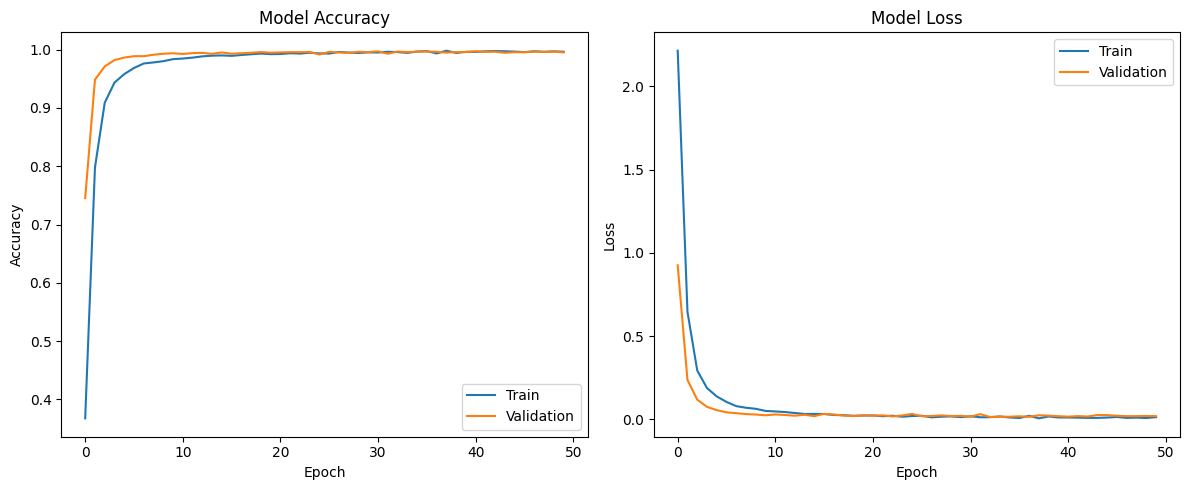

In [ ]:
plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')

plt.tight_layout()
plt.show()

### Error Analysis: Visualizing Misclassifications

To understand where the model is failing, we visualize the images from the test set where the predicted label does not match the true label.

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Get predictions for the test set
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Identify misclassified examples
misclassified_indices = np.where(y_pred != y_test)[0]

print(f"Total misclassified examples: {len(misclassified_indices)}")

# Select a few misclassified examples for Grad-CAM visualization
# We'll pick the first 5 misclassified examples, if available
num_examples_to_show = min(10, len(misclassified_indices))
selected_misclassified_indices = misclassified_indices[:num_examples_to_show]

print(f"Selected {num_examples_to_show} misclassified examples for Grad-CAM.")

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Total misclassified examples: 453
Selected 10 misclassified examples for Grad-CAM.


### Visualize Misclassified Examples

Let's visualize some of the misclassified examples to get a qualitative understanding of the errors the model is making.

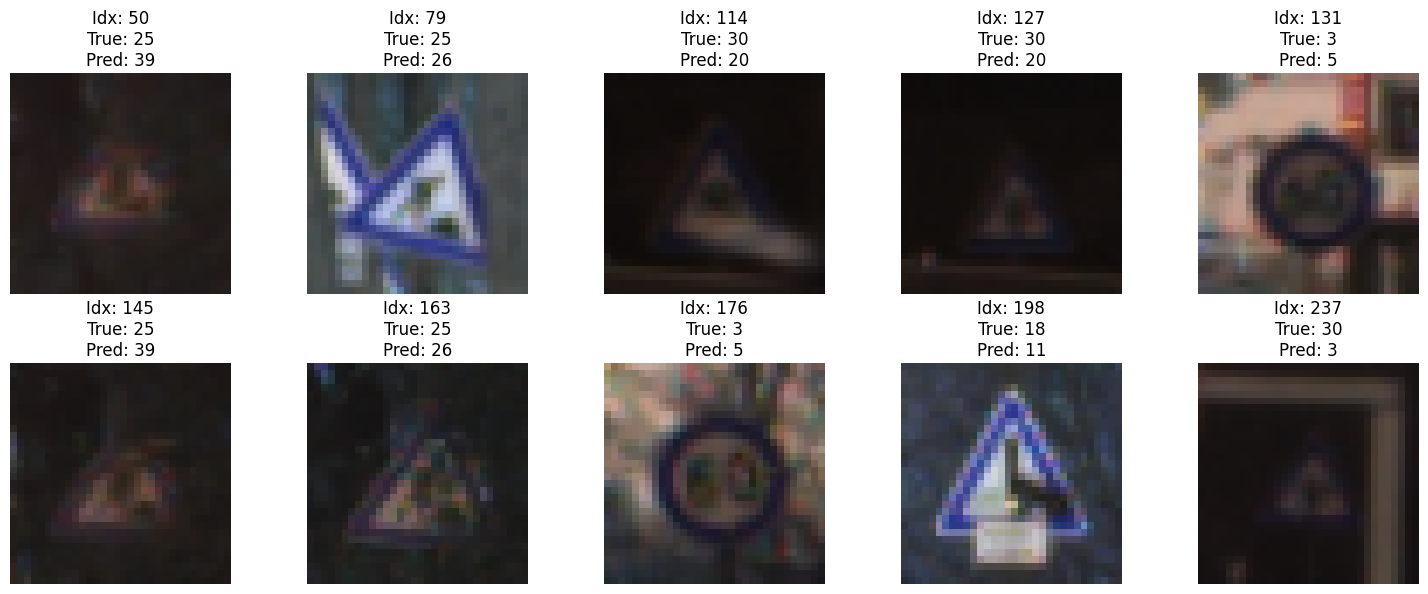

In [ ]:
plt.figure(figsize=(15, 6))
for i, idx in enumerate(selected_misclassified_indices):
    if i >= 10:
        break
    plt.subplot(2, 5, i + 1)
    plt.imshow((X_test[idx] * 255).astype(np.uint8))
    plt.title(f"True: {y_test[idx]}\nPred: {y_pred[idx]}", fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.show()

### Evaluation Metrics for Cnn model.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import time

# Accuracy is already calculated during model evaluation
print(f"Test Accuracy: {accuracy:.4f}")

# Calculate Precision, Recall, and F1-score
# Since y_test and y_pred are integer labels for classes, we can calculate these directly.
# Use 'average=weighted' to account for class imbalance.
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Test Precision (weighted): {precision:.4f}")
print(f"Test Recall (weighted): {recall:.4f}")
print(f"Test F1-Score (weighted): {f1:.4f}")

# Estimate Frames Per Second (FPS) for prediction
start_time = time.time()
_ = model.predict(X_test)
end_time = time.time()

prediction_time = end_time - start_time
num_test_samples = len(X_test)

# Calculate FPS
fps = num_test_samples / prediction_time

print(f"Prediction time for {num_test_samples} samples: {prediction_time:.2f} seconds")
print(f"Estimated Frames Per Second (FPS): {fps:.2f}")

Test Accuracy: 0.9641
Test Precision (weighted): 0.9668
Test Recall (weighted): 0.9641
Test F1-Score (weighted): 0.9642
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Prediction time for 12630 samples: 1.77 seconds
Estimated Frames Per Second (FPS): 7142.03


# 2.Classification with mobilenet
* MobileNetV3 uses Depthwise Separable Convolutions and Squeeze-and-Excitation (SE) modules.




In [ ]:
import os
import kagglehub
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# ---------------------------------------------------------
# Step 1: Download GTSRB Dataset
# ---------------------------------------------------------
dataset_path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

print(f"Dataset downloaded to: {dataset_path}")

train_dir = os.path.join(dataset_path, "Train")
if not os.path.exists(train_dir):
    train_dir = os.path.join(dataset_path, "train")

# ---------------------------------------------------------
# Step 2: Transforms
# ---------------------------------------------------------
IMG_SIZE = (224, 224)

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

val_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

# ---------------------------------------------------------
# Step 3: Create TWO datasets
# (different transforms)
# ---------------------------------------------------------
train_dataset_full = datasets.ImageFolder(
    root=train_dir,
    transform=train_transforms
)

val_dataset_full = datasets.ImageFolder(
    root=train_dir,
    transform=val_transforms
)

# ---------------------------------------------------------
# Step 4: Train / Validation split
# ---------------------------------------------------------
generator = torch.Generator().manual_seed(42)

num_samples = len(train_dataset_full)
train_size = int(0.8 * num_samples)
val_size = num_samples - train_size

indices = torch.randperm(num_samples, generator=generator)

train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = torch.utils.data.Subset(
    train_dataset_full,
    train_indices
)

val_dataset = torch.utils.data.Subset(
    val_dataset_full,
    val_indices
)

# ---------------------------------------------------------
# Step 5: DataLoaders
# ---------------------------------------------------------
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print(f"Training images   : {len(train_dataset)}")
print(f"Validation images : {len(val_dataset)}")
print(f"Number of classes : {len(train_dataset_full.classes)}")

print("\nImageFolder label mapping:")
print(train_dataset_full.class_to_idx)

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Dataset downloaded to: /kaggle/input/gtsrb-german-traffic-sign
Training images   : 31367
Validation images : 7842
Number of classes : 43

ImageFolder label mapping:
{'0': 0, '1': 1, '10': 2, '11': 3, '12': 4, '13': 5, '14': 6, '15': 7, '16': 8, '17': 9, '18': 10, '19': 11, '2': 12, '20': 13, '21': 14, '22': 15, '23': 16, '24': 17, '25': 18, '26': 19, '27': 20, '28': 21, '29': 22, '3': 23, '30': 24, '31': 25, '32': 26, '33': 27, '34': 28, '35': 29, '36': 30, '37': 31, '38': 32, '39': 33, '4': 34, '40': 35, '41': 36, '42': 37, '5': 38, '6': 39, '7': 40, '8': 41, '9': 42}


In [ ]:
import pandas as pd
from PIL import Image

# ---------------------------------------------------------
# Step 5: Define Custom Dataset class for GTSRB Test Set
# ---------------------------------------------------------
import os
import pandas as pd
from PIL import Image
import torch

class_to_idx = train_dataset_full.class_to_idx

class GTSRBTestDataset(torch.utils.data.Dataset):
    def __init__(self, root_dir, csv_file, transform=None):
        self.root_dir = root_dir
        self.df = pd.read_csv(csv_file)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        img_path = os.path.join(
            self.root_dir,
            self.df.iloc[idx]["Path"]
        )

        image = Image.open(img_path).convert("RGB")

        #label = int(self.df.iloc[idx]["ClassId"])

        label = class_to_idx[str(self.df.iloc[idx]["ClassId"])]

        if self.transform:
            image = self.transform(image)

        return image, label
# ---------------------------------------------------------
# Step 6: Locate Test Directory & CSV Path
# ---------------------------------------------------------
test_dir = dataset_path  # The root downloaded folder contains Test.csv and Test/
test_csv = os.path.join(dataset_path, "Test.csv")

# Ensure Test.csv exists (fallback check for lowercase 'test.csv')
if not os.path.exists(test_csv):
    test_csv = os.path.join(dataset_path, "test.csv")

# ---------------------------------------------------------
# Step 7: Create Test Dataset and DataLoader
# ---------------------------------------------------------
# Use val_transforms for testing (Resize to 224x224 + ImageNet Normalization)
# Pass the class_to_idx map from the training dataset to ensure correct label alignment
test_dataset = GTSRBTestDataset(
    root_dir=dataset_path,
    csv_file=test_csv,
    transform=val_transforms
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print(f"Total Test Images: {len(test_dataset)}") # Expected: 12,630 samples

Total Test Images: 12630


In [ ]:
import torch.nn as nn
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small

# 1. Load Pretrained MobileNetV3-Small
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)

# 2. Modify Output Head for 43 Classes
in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, 43)
model = model.to(device)
# 3. Define Optimizer and Loss Function
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    [
        {"params": model.features.parameters(), "lr": 1e-4},       # Backbone: Gentle fine-tuning
        {"params": model.classifier.parameters(), "lr": 1e-3}      # New Head: Faster learning
    ],
    weight_decay=1e-2  # Prevents overfitting on fine-tuning
)
#optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001)
#print(model)

Using device: cuda


In [ ]:
import tqdm
from google.colab import files
EPOCHS = 20
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
best_val_acc = 0.0  # Track best validation accuracy to save the best model

# Initialize lists to store metrics for plotting
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):
  # ==========================================
  # STAGE 1: TRAINING PHASE
  # ==========================================
  model.train()  # Set model to training mode
  train_loss = 0.0
  train_correct = 0
  total_train_samples = 0

  print(f"\nEpoch {epoch+1}/{EPOCHS} - Training...")
  for images, labels in tqdm.tqdm(train_loader, desc=f"Training Epoch {epoch+1}"):
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    # Track metrics
    train_loss += loss.item() * images.size(0)
    _, preds = torch.max(outputs, 1)
    train_correct += torch.sum(preds == labels.data).item()
    total_train_samples += labels.size(0)

  epoch_train_loss = train_loss / total_train_samples
  epoch_train_acc = (train_correct / total_train_samples) * 100

  # Store training metrics
  train_losses.append(epoch_train_loss)
  train_accuracies.append(epoch_train_acc)

  # ==========================================
  # STAGE 2: VALIDATION PHASE
  # ==========================================
  model.eval()  # Set model to evaluation mode
  val_loss = 0.0
  val_correct = 0
  total_val_samples = 0

  print(f"Epoch {epoch+1}/{EPOCHS} - Validating...")
  # Disable gradient computation for speed and memory efficiency
  with torch.no_grad():
    for images, labels in tqdm.tqdm(val_loader, desc=f"Validation Epoch {epoch+1}"):
      images, labels = images.to(device), labels.to(device)

      # Forward pass
      outputs = model(images)
      loss = criterion(outputs, labels)

      # Track validation metrics
      val_loss += loss.item() * images.size(0)
      _, preds = torch.max(outputs, 1)
      val_correct += torch.sum(preds == labels.data).item()
      total_val_samples += labels.size(0)

  epoch_val_loss = val_loss / total_val_samples
  epoch_val_acc = (val_correct / total_val_samples) * 100

  # Store validation metrics
  val_losses.append(epoch_val_loss)
  val_accuracies.append(epoch_val_acc)

  scheduler.step()
  # Print Epoch Summary
  print(f"Epoch [{epoch+1}/{EPOCHS}]")
  print(
      f"  Train Loss: {epoch_train_loss:.4f} | Train Acc:"
      f" {epoch_train_acc:.2f}%"
  )
  print(
      f"  Val Loss:   {epoch_val_loss:.4f} | Val Acc:   {epoch_val_acc:.2f}%\n"
  )

  # ==========================================
  # STAGE 3: SAVE BEST MODEL WEIGHTS
  # ==========================================
  if epoch_val_acc > best_val_acc:
    best_val_acc = epoch_val_acc
    torch.save(model.state_dict(), "/content/gtsrb_mobilenetv3_224size.pth")
    print(
        f"  --> Saved new best model checkpoint! (Val Acc: {best_val_acc:.2f}%)\n"
    )

print(
    f"Training complete! Highest Validation Accuracy achieved:"
    f" {best_val_acc:.2f}%"
)
files.download("/content/gtsrb_mobilenetv3_224size.pth")



Epoch 1/20 - Training...


Training Epoch 1: 100%|██████████| 491/491 [01:57<00:00,  4.18it/s]


Epoch 1/20 - Validating...


Validation Epoch 1: 100%|██████████| 123/123 [00:16<00:00,  7.59it/s]


Epoch [1/20]
  Train Loss: 0.4379 | Train Acc: 86.75%
  Val Loss:   0.0665 | Val Acc:   97.97%

  --> Saved new best model checkpoint! (Val Acc: 97.97%)


Epoch 2/20 - Training...


...

Epoch 20/20 - Validating...


Validation Epoch 20: 100%|██████████| 123/123 [00:16<00:00,  7.51it/s]

Epoch [20/20]
  Train Loss: 0.0002 | Train Acc: 100.00%
  Val Loss:   0.0030 | Val Acc:   99.91%

Training complete! Highest Validation Accuracy achieved: 99.92%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

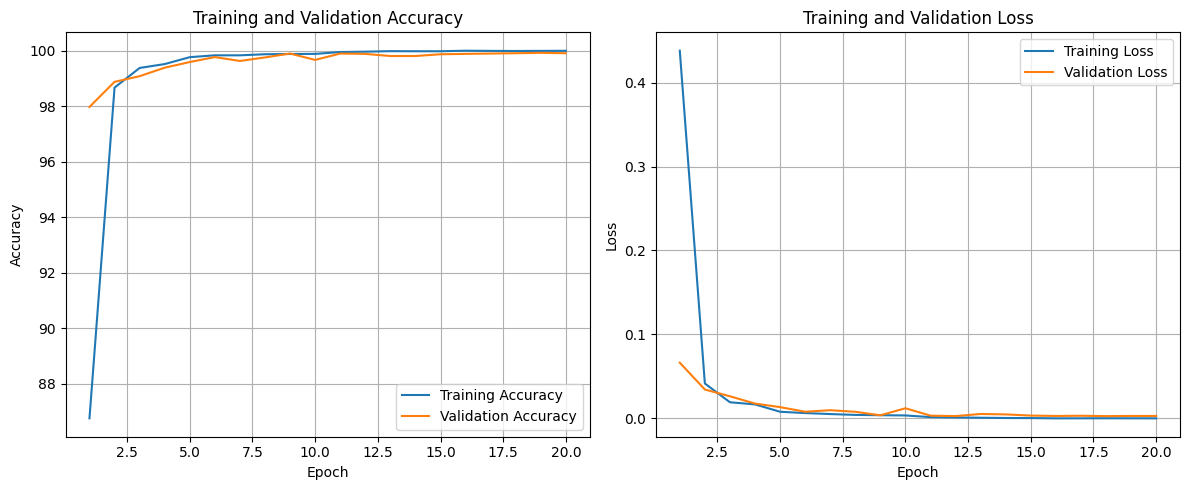

In [ ]:
import matplotlib.pyplot as plt

# Assuming train_losses, train_accuracies, val_losses, val_accuracies are populated from the training loop

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Plot training & validation accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracies, label='Training Accuracy')
plt.plot(epochs_range, val_accuracies, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot training & validation loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_losses, label='Training Loss')
plt.plot(epochs_range, val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()


Calculating losses for validation set...
highet losses all: 7842

Displaying top 10 images with highest losses:


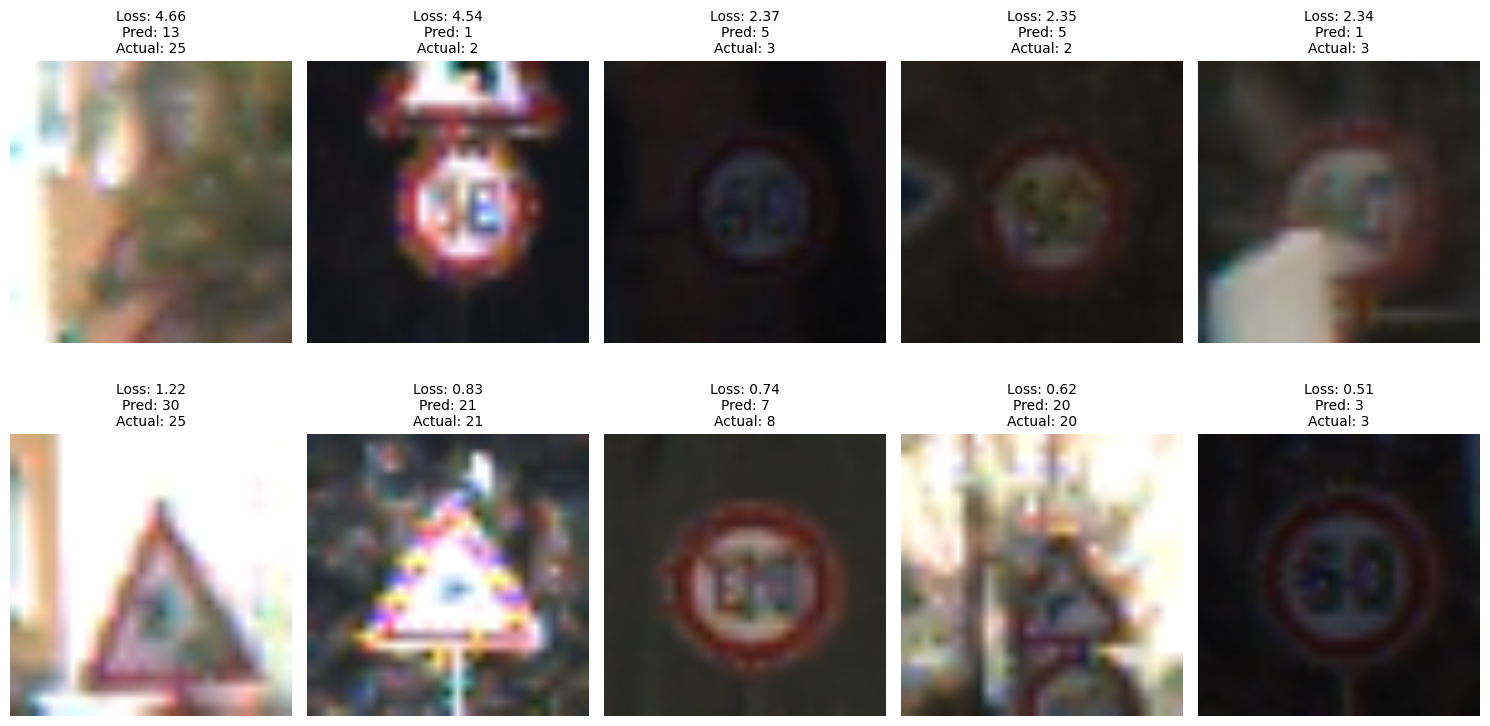

Finished displaying images with highest losses.


In [ ]:
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Make sure the model is on the correct device and in evaluation mode
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

# Temporarily change criterion to get per-sample loss
# Store the original criterion settings to restore them later if necessary
original_criterion_reduction = criterion.reduction
criterion = torch.nn.CrossEntropyLoss(reduction='none')

all_losses = []
all_predicted_labels = []
all_actual_labels = []
all_images_for_display = []

print("Calculating losses for validation set...")
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        per_sample_losses = criterion(outputs, labels)  # Now this gives loss for each sample
        predicted_labels = torch.argmax(outputs, dim=1)

        all_losses.extend(per_sample_losses.cpu().numpy())
        all_predicted_labels.extend(predicted_labels.cpu().numpy())
        all_actual_labels.extend(labels.cpu().numpy())
        all_images_for_display.extend(images.cpu())  # Store CPU tensors for display

# Restore original criterion (although not strictly necessary for this task, good practice)
criterion.reduction = original_criterion_reduction

# Combine all information
results = []
for i in range(len(all_losses)):
    results.append({
        'loss': all_losses[i],
        'predicted': all_predicted_labels[i],
        'actual': all_actual_labels[i],
        'image': all_images_for_display[i]
    })

# Sort by loss in descending order
results.sort(key=lambda x: x['loss'], reverse=True)

# Select the top 10 highest loss images
top_10_highest_loss = results[:10]
print("highet losses all:" ,len(results))
print(f"\nDisplaying top {len(top_10_highest_loss)} images with highest losses:")

# Denormalization parameters (imagenet_mean and imagenet_std are defined in previous cells)
mean_tensor = torch.tensor(imagenet_mean).view(3, 1, 1)
std_tensor = torch.tensor(imagenet_std).view(3, 1, 1)

# Get class names (assuming full_train_dataset.classes is available from previous cells)
# These are typically strings like '00000', '00001', etc., which is fine.
class_names = train_dataset_full.classes

plt.figure(figsize=(15, 8))
for i, item in enumerate(top_10_highest_loss):
    img_tensor = item['image']
    predicted_label_id = item['predicted']
    actual_label_id = item['actual']
    loss_value = item['loss']

    # Denormalize image
    denormalized_img_tensor = img_tensor * std_tensor + mean_tensor
    # Clamp values to [0, 1] to ensure valid image data for display
    denormalized_img_tensor = torch.clamp(denormalized_img_tensor, 0, 1)

    # Convert to numpy and transpose for matplotlib (C, H, W -> H, W, C)
    img_np = denormalized_img_tensor.numpy().transpose(1, 2, 0)

    # Get class names, if available, otherwise use IDs
    predicted_name = class_names[predicted_label_id] if predicted_label_id < len(class_names) else str(predicted_label_id)
    actual_name = class_names[actual_label_id] if actual_label_id < len(class_names) else str(actual_label_id)

    plt.subplot(2, 5, i + 1)
    plt.imshow(img_np)
    plt.title(f"Loss: {loss_value:.2f}\nPred: {predicted_name}\nActual: {actual_name}", fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()
print("Finished displaying images with highest losses.")


### Grad-CAM Visualization for Highest-Loss Images

To gain deeper insights into the model's decision-making process, especially for images where it performs poorly (high loss), we will implement Grad-CAM (Gradient-weighted Class Activation Mapping). Grad-CAM generates a heatmap highlighting the regions in the input image that were most important for the model's prediction of a specific class. This can help us understand if the model is focusing on relevant features or being distracted by noise or irrelevant parts of the image.

Generating Grad-CAM heatmaps for top 10 highest-loss images...


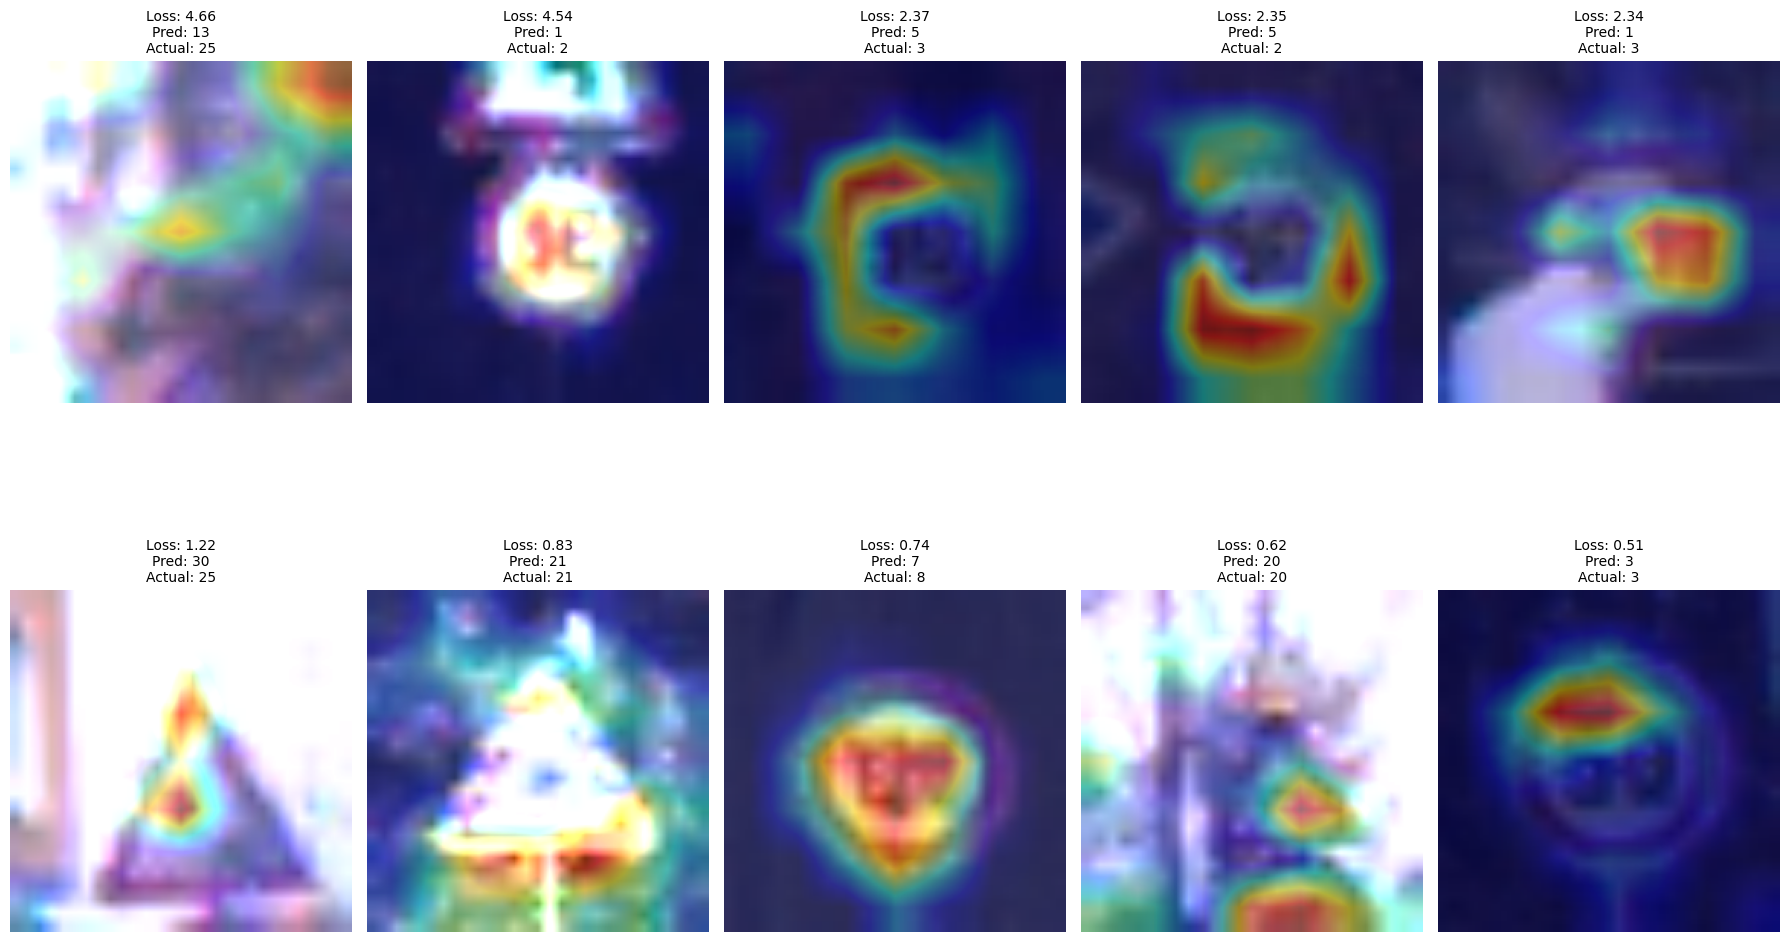

Finished generating Grad-CAM heatmaps.


In [ ]:
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2
# Hooks to store activations and gradients
activations = None
grads = None

def save_activations(module, input, output):
    global activations
    activations = output

def save_gradients(module, grad_input, grad_output):
    global grads
    grads = grad_output[0]

def generate_grad_cam_pytorch(model, input_image_tensor, target_class_idx, target_layer):
    # Ensure model is in evaluation mode
    model.eval()

    # Register hooks
    # The last convolutional layer in MobileNetV3 Small's 'features' block
    # For mobilenet_v3_small, a good target is model.features[-1][0] or model.features[12][0]
    # Let's target the last Conv2d in the features block before pooling
    # From inspection, model.features[12][0] is the last Conv2d in the feature extractor
    hook_a = target_layer.register_forward_hook(save_activations)
    hook_g = target_layer.register_full_backward_hook(save_gradients)

    # Forward pass
    output = model(input_image_tensor)

    # Zero gradients for all parameters
    model.zero_grad()

    # Get the score for the target class
    target_score = output[0, target_class_idx]

    # Backward pass to get gradients
    target_score.backward(retain_graph=True) # retain_graph=True if we do more backward passes

    # Pooled gradients (alpha_k)
    # shape: (batch_size, channels, H, W) -> (batch_size, channels)
    pooled_gradients = torch.mean(grads, dim=[2, 3])

    # Weight the activations
    # shape: (batch_size, channels, H, W) * (batch_size, channels, 1, 1)
    for i in range(activations.shape[1]):
        activations[:, i, :, :] *= pooled_gradients[:, i]

    # Sum across channels and apply ReLU
    # shape: (batch_size, H, W)
    heatmap = torch.sum(activations, dim=1).squeeze()
    heatmap = F.relu(heatmap)

    # Normalize the heatmap
    heatmap /= torch.max(heatmap)

    # Remove hooks
    hook_a.remove()
    hook_g.remove()

    return heatmap.detach().cpu().numpy()

# Identify the target layer for Grad-CAM
# For MobileNetV3 Small, model.features[12][0] is the Conv2d layer right before the final pooling and classifier.
# This is a common choice for the last convolutional layer output.
target_grad_cam_layer = model.features[12][0]

plt.figure(figsize=(18, 12))
print("Generating Grad-CAM heatmaps for top 10 highest-loss images...")

for i, item in enumerate(top_10_highest_loss):
    img_tensor = item['image'].to(device) # Get the original normalized tensor, move to device
    predicted_label_id = item['predicted']
    actual_label_id = item['actual']
    loss_value = item['loss']

    # Add batch dimension for model input
    input_image_tensor = img_tensor.unsqueeze(0)

    # Generate Grad-CAM heatmap using the predicted class for misclassified examples
    heatmap = generate_grad_cam_pytorch(model, input_image_tensor, predicted_label_id, target_grad_cam_layer)

    # Denormalize the original image for display
    mean_tensor_dev = mean_tensor.to(device)
    std_tensor_dev = std_tensor.to(device)
    denormalized_img_tensor = img_tensor * std_tensor_dev + mean_tensor_dev
    denormalized_img_tensor = torch.clamp(denormalized_img_tensor, 0, 1) # Clamp to [0, 1]
    img_np = denormalized_img_tensor.cpu().numpy().transpose(1, 2, 0)

    # Resize heatmap to match image size
    heatmap_resized = cv2.resize(heatmap, (img_np.shape[1], img_np.shape[0]))
    heatmap_resized = np.uint8(255 * heatmap_resized)
    heatmap_colored = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    # Superimpose heatmap on original image
    superimposed_img = heatmap_colored * 0.4 + img_np * 255 # Adjust weights as needed
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)

    predicted_name = class_names[predicted_label_id] if predicted_label_id < len(class_names) else str(predicted_label_id)
    actual_name = class_names[actual_label_id] if actual_label_id < len(class_names) else str(actual_label_id)

    plt.subplot(2, 5, i + 1)
    plt.imshow(superimposed_img)
    plt.title(f"Loss: {loss_value:.2f}\nPred: {predicted_name}\nActual: {actual_name}", fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()
print("Finished generating Grad-CAM heatmaps.")



*   Evaluation of the Mobilenet model on testset



In [ ]:
import os
import time
import torch
import torch.nn as nn
from torchvision import models, transforms
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torchvision.models import mobilenet_v3_small

# 1. Setup device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Re-create the EXACT architecture used during training
# (Note: weights=None or default works, as parameters will be overwritten)
model = mobilenet_v3_small()
in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, 43)

# 3. Load the saved state dictionary
checkpoint_path = "/content/gtsrb_mobilenetv3_224size.pth"
state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(state_dict)

# 4. Move model to device and enable EVALUATION mode (CRITICAL!)
model = model.to(device)
model.eval()
# =====================================================================
# 2. Verify Label Mapping (Fixing ImageFolder vs CSV mismatch)
# =====================================================================
# Use the exact class_to_idx from your training dataset
# full_train_dataset.class_to_idx maps folder name string '00001' to index 1

# =====================================================================
# 3. Corrected Evaluation Loop
# =====================================================================
all_preds = []
all_labels = []

# Warmup pass
dummy = torch.randn(1, 3, 224, 224).to(device)
with torch.no_grad():
    for _ in range(10):
        _ = model(dummy)

if device.type == 'cuda':
    torch.cuda.synchronize()

start_time = time.time()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

if device.type == 'cuda':
    torch.cuda.synchronize()

end_time = time.time()

total_time = end_time - start_time
fps = len(all_labels) / total_time

acc = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average='weighted', zero_division=0
)

print(f"\n=========================================")
print(f" EVALUATION RESULTS: MobileNetV3 Small (FIXED)")
print(f"=========================================")
print(f" Test Accuracy:           {acc:.4f}")
print(f" Test Precision (weighted): {precision:.4f}")
print(f" Test Recall (weighted):    {recall:.4f}")
print(f" Test F1-Score (weighted):  {f1:.4f}")
print(f" Inference Time ({len(all_labels)} samples): {total_time:.2f} seconds")
print(f" Estimated FPS:           {fps:.2f}")
print(f"=========================================\n")


 EVALUATION RESULTS: MobileNetV3 Small (FIXED)
 Test Accuracy:           0.9790
 Test Precision (weighted): 0.9791
 Test Recall (weighted):    0.9790
 Test F1-Score (weighted):  0.9787
 Inference Time (12630 samples): 28.21 seconds
 Estimated FPS:           447.65



# 3.Detection using YOLO nano version model on (GTSDB) dataset.


In [ ]:
!pip install ultralytics
import yaml
import os
import kagglehub
from ultralytics import YOLO
import matplotlib.pyplot as plt
import random
import cv2


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
print('Downloading the GTSDB dataset from icebearogo...')
yolo_dataset_path = kagglehub.dataset_download("icebearogo/german-traffic-sign-detection-gtsdb-dataset")
print(f"Dataset downloaded to: {yolo_dataset_path}")

# List contents of the downloaded directory
print("\nContents of the downloaded dataset directory:")
for root, dirs, files in os.walk(yolo_dataset_path):
    level = root.replace(yolo_dataset_path, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 4 * (level + 1)
    # Instead of printing all files, print the length of the files list
    if files:
        print(f'{subindent}{len(files)} files')


100%|██████████| 234M/234M [00:03<00:00, 73.0MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/icebearogo/german-traffic-sign-detection-gtsdb-dataset/versions/1

Contents of the downloaded dataset directory:
1/
    GTSDB_Train_and_Test/
        1 files
        Train/
            images/
                600 files
            labels/
                506 files
        Test/
            images/
                300 files
            labels/
                235 files


## YOLOv8 Object Detection Pipeline for GTSDB

This section will cover the following steps to train and evaluate a YOLOv8 model for traffic sign detection on the GTSDB dataset:

1.  **Dataset Preparation**: Convert the GTSDB annotations to YOLO format and organize the dataset for training.
2.  **Configuration (`data.yaml`)**: Create the `data.yaml` file required by YOLOv8 to specify dataset paths and class names.
3.  **Model Training**: Load a pre-trained YOLOv8 model and fine-tune it on the GTSDB dataset.
4.  **Model Evaluation**: Assess the performance of the trained model.
5.  **Inference**: Demonstrate how to use the trained model for predictions on new images.

### 2. Create `data.yaml` Configuration File

YOLOv8 requires a `data.yaml` file that points to the training and validation image directories and lists the names of the classes. We will generate this file based on our prepared dataset structure.

In [ ]:
import os
import yaml

# ---------------------------------------------------------
# Step 1: Define Paths & Setup Symlink
# ---------------------------------------------------------
# Replace yolo_dataset_path with your base dataset variable
yolo_data_root_original = os.path.join(
    yolo_dataset_path, "GTSDB_Train_and_Test"
)
symlink_target_path = "/content/GTSDB_Train_and_Test"

if not os.path.exists(symlink_target_path):
    os.symlink(yolo_data_root_original, symlink_target_path)
    print(
        f"Created symlink from {yolo_data_root_original} to"
        f" {symlink_target_path}"
    )
else:
    print(f"Symlink already exists at {symlink_target_path}")

train_images_path_fixed = os.path.join(symlink_target_path, "Train", "images")
val_images_path_fixed = os.path.join(symlink_target_path, "Test", "images")
train_labels_path = os.path.join(symlink_target_path, "Train", "labels")
val_labels_path = os.path.join(symlink_target_path, "Test", "labels")

# ---------------------------------------------------------
# Step 2: Remap All Label .txt Files to 1 Class (Class ID 0)
# ---------------------------------------------------------
label_dirs = [train_labels_path, val_labels_path]

for label_dir in label_dirs:
    if not os.path.exists(label_dir):
        print(f"Warning: Directory not found: {label_dir}")
        continue

    file_count = 0
    for label_file in os.listdir(label_dir):
        if not label_file.endswith(".txt"):
            continue

        file_path = os.path.join(label_dir, label_file)

        # Read original annotations
        with open(file_path, "r") as f:
            lines = f.readlines()

        new_lines = []
        for line in lines:
            parts = line.strip().split()
            if len(parts) >= 5:
                # Force class index to 0 for generic sign detection
                parts[0] = "0"
                new_lines.append(" ".join(parts) + "\n")

        # Overwrite file with updated class ID 0
        with open(file_path, "w") as f:
            f.writelines(new_lines)

        file_count += 1

    print(f"Successfully converted labels in {label_dir} ({file_count} files)")

# ---------------------------------------------------------
# Step 3: Create 1-Class gtsdb.yaml Configuration
# ---------------------------------------------------------
gtsdb_1_class = {0: "traffic_sign"}

data_yaml_path = os.path.join("/content", "gtsdb.yaml")

data_yaml_content_fixed = {
    "train": train_images_path_fixed,
    "val": val_images_path_fixed,
    "nc": 1,
    "names": gtsdb_1_class,
}

# Write the updated data.yaml file
with open(data_yaml_path, "w") as f:
    yaml.dump(data_yaml_content_fixed, f, default_flow_style=False)

print(f"\nUpdated 1-Class data.yaml at: {data_yaml_path}")
print("--------------------------------------------------")
with open(data_yaml_path, "r") as f:
    print(f.read())

Created symlink from /root/.cache/kagglehub/datasets/icebearogo/german-traffic-sign-detection-gtsdb-dataset/versions/1/GTSDB_Train_and_Test to /content/GTSDB_Train_and_Test
Successfully converted labels in /content/GTSDB_Train_and_Test/Train/labels (506 files)
Successfully converted labels in /content/GTSDB_Train_and_Test/Test/labels (235 files)

Updated 1-Class data.yaml at: /content/gtsdb.yaml
--------------------------------------------------
names:
  0: traffic_sign
nc: 1
train: /content/GTSDB_Train_and_Test/Train/images
val: /content/GTSDB_Train_and_Test/Test/images



Detected Class ID: 0 in /content/GTSDB_Train_and_Test/Train/labels/00011.txt


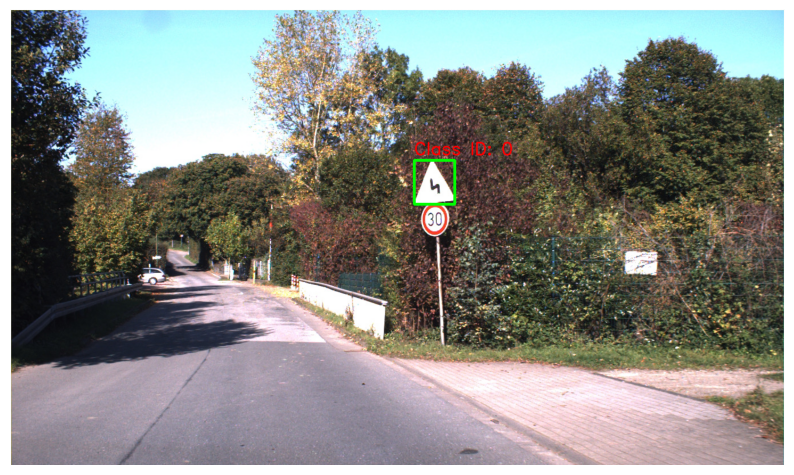

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Pick an image and label pair to inspect
img_path = '/content/GTSDB_Train_and_Test/Train/images/00011.jpg'
txt_path = '/content/GTSDB_Train_and_Test/Train/labels/00011.txt'

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w, _ = img.shape

if os.path.exists(txt_path):
    with open(txt_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            class_id = int(parts[0])
            x_center, y_center, bbox_w, bbox_h = map(float, parts[1:])

            x1 = int((x_center - bbox_w / 2) * w)
            y1 = int((y_center - bbox_h / 2) * h)
            x2 = int((x_center + bbox_w / 2) * w)
            y2 = int((y_center + bbox_h / 2) * h)

            print(f"Detected Class ID: {class_id} in {txt_path}")
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
            cv2.putText(img, f"Class ID: {class_id}", (x1, y1 - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)

plt.figure(figsize=(10, 6))
plt.imshow(img)
plt.axis('off')
plt.show()

### 3. Model Training

Now we can load a pre-trained YOLOv8 model (e.g., `yolov8n.pt` for nano version) and train it on our prepared GTSDB dataset. The `model.train()` function handles the entire training loop.

In [ ]:
import os
import yaml
from ultralytics import YOLO


model = YOLO('yolov8n.pt') # Load a pre-trained YOLOv8n model

# Train the model
# The data.yaml_path variable was defined in the previous cell (e8a5c4ae) but is now updated.
results = model.train(data=data_yaml_path, epochs=60,weight_decay=0.0005,cos_lr=True, imgsz=1024,batch=16, name='yolov8_gtsdb_60epo_btc16_1024size')

print("Training complete.")


Ultralytics 8.4.116 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/gtsdb.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8_gtsdb_60epo_btc16_1024size, nbs=64,

### 4. Model Evaluation

After training, it's crucial to evaluate the model's performance on the validation set. YOLOv8's `model.val()` function provides various metrics, including Mean Average Precision (mAP).

In [ ]:
from ultralytics import YOLO

# Load the best trained model
model = YOLO("/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.pt")

# 2. Run evaluation on the TEST split explicitly
metrics = model.val()  # or split="val" if you don't have a separate test set in data.yaml

# 3. Print out the key metrics for your report
print("\n--- YOLO Detection Metrics ---")
print(f"Precision (mP):     {metrics.box.mp:.4f}")
print(f"Recall (mR):        {metrics.box.mr:.4f}")
print(f"mAP@50:            {metrics.box.map50:.4f}")
print(f"mAP@50-95:         {metrics.box.map:.4f}")

# 4. Print speed & latency breakdown (Inference, Preprocessing, Postprocessing)
print("\n--- Latency Breakdown (ms) ---")
print(f"Pre-process time:   {metrics.speed['preprocess']:.2f} ms")
print(f"Inference time:     {metrics.speed['inference']:.2f} ms")
print(f"Post-process time:  {metrics.speed['postprocess']:.2f} ms")
# 4. Print Operational Complexity
model.info()  # Displays Layers, Parameters, and GFLOPs

Ultralytics 8.4.116 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2265.1±501.3 MB/s, size: 152.1 KB)
val: Scanning /root/.cache/kagglehub/datasets/icebearogo/german-traffic-sign-detection-gtsdb-dataset/versions/1/GTSDB_Train_and_Test/Test/labels.cache... 235 images, 65 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 139.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.6it/s 7.2s
                   all        300        361       0.91       0.92      0.965      0.814
Speed: 5.4ms preprocess, 5.8ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/runs/detect/val-9

--- YOLO Detection Metrics ---
Precision (mP):     0.9096
Recall (mR):        0.9197
mAP@50:            0.9652
mAP@50-95:         0.8140

--- Latency Breakdown (ms) ---
Pre-

(73, 3005843, 0, 8.0827392)

# Flops

In [ ]:
import torch
import torch.nn as nn
from thop import profile, clever_format
from torchvision.models import mobilenet_v3_small

# 1. Instantiate your MobileNetV3 model architecture
mobilenet_model_flops = mobilenet_v3_small()
# Modify the classifier head to match the number of classes (43)
in_features_mobilenet = mobilenet_model_flops.classifier[3].in_features
mobilenet_model_flops.classifier[3] = nn.Linear(in_features_mobilenet, 43)

# Load the trained weights into the model
checkpoint_path = "/content/gtsrb_mobilenetv3_224size.pth" # Path to your trained MobileNetV3 weights
mobilenet_model_flops.load_state_dict(torch.load(checkpoint_path, map_location='cpu'))
mobilenet_model_flops.eval()

# 2. Define standard input shape (1 image, 3 channels, 224x224)
# MobileNetV3 was trained with 224x224 images as defined by IMG_SIZE
input_tensor_mobilenet = torch.randn(1, 3, 224, 224)

# 3. Calculate Multiply-Accumulate Operations (MACs) and Parameters
macs, params = profile(mobilenet_model_flops, inputs=(input_tensor_mobilenet, ))

# Note: 1 MAC ≈ 2 FLOPs (1 Multiplication + 1 Addition in many contexts, but often just MACs are reported)
# For a precise conversion, typically FLOPs = 2 * MACs for deep learning models.
flops = macs * 2

# 4. Format into readable GFLOPs / MFLOPs
macs_str, params_str = clever_format([macs, params], "%.3f")

print("\n--- MobileNetV3 FLOPs and Parameters ---")
print(f"Total MACs:   {macs_str}")
print(f"Total FLOPs:  {flops / 1e9:.4f} GFLOPs") # Reporting in GFLOPs
print(f"Parameters:   {params_str}")
print("-----------------------------------------")

[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register zero_ops() for <class 'torchvision.ops.misc.Conv2dNormActivation'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.container.Sequential'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.dropout.Dropout'>.

--- MobileNetV3 FLOPs and Parameters ---
Total MACs:   61.498M
Total FLOPs:  0.1230 GFLOPs
Parameters:   1.562M
-----------------------------------------


#latency, memory, and FPS benchmarks on both CPU and GPU:

In [ ]:
import os
import time
import torch
import numpy as np
import cv2
from ultralytics import YOLO
from torchvision import transforms
from PIL import Image

# ---------------------------------------------------------
# 1. Setup & Load Models
# ---------------------------------------------------------
device_gpu = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device_cpu = torch.device('cpu')

# Load Stage 1 (YOLO Detector)
detector = YOLO('/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.pt') # Updated path for YOLOv8 model

# Load Stage 2 (MobileNetV3 Classifier)
from torchvision.models import mobilenet_v3_small
classifier = mobilenet_v3_small()
classifier.classifier[3] = torch.nn.Linear(classifier.classifier[3].in_features, 43)
classifier.load_state_dict(torch.load('/content/gtsrb_mobilenetv3_224size.pth', map_location='cpu')) # Updated path for MobileNetV3 model

classifier_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Generate a synthetic test image (simulating camera frame: 1920x1080)
#dummy_image = np.uint8(np.random.randint(0, 255, (1080, 1920, 3)))
dummy_image = np.uint8(np.random.randint(0, 255, (1024, 1024, 3)))

# ---------------------------------------------------------
# 2. Benchmark Pipeline Latency & FPS
# ---------------------------------------------------------
def profile_pipeline(detector_model, classifier_model, image, target_device, runs=50):
    classifier_model.to(target_device)
    classifier_model.eval()

    # Warmup runs (essential to prime CUDA kernels & CPU caching)
    for _ in range(10):
        _ = detector_model(image, verbose=False)

    latencies_stage1 = []
    latencies_stage2 = []
    latencies_total = []

    for _ in range(runs):
        t0 = time.perf_counter()

        # --- Stage 1: YOLO Detection ---
        det_results = detector_model(image, device=0 if target_device.type=='cuda' else 'cpu', verbose=False)
        t1 = time.perf_counter()

        # --- Pipeline Bounding Box Extraction & Cropping ---
        boxes = det_results[0].boxes.xyxy.cpu().numpy()

        # --- Stage 2: MobileNet Classification ---
        if len(boxes) > 0:
            x1, y1, x2, y2 = map(int, boxes[0])
            crop = image[y1:y2, x1:x2]
            if crop.size != 0:
                crop_pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
                tensor = classifier_transforms(crop_pil).unsqueeze(0).to(target_device)
                with torch.no_grad():
                    _ = classifier_model(tensor)

        t2 = time.perf_counter()

        latencies_stage1.append((t1 - t0) * 1000) # ms
        latencies_stage2.append((t2 - t1) * 1000) # ms
        latencies_total.append((t2 - t0) * 1000)  # ms

    avg_stage1 = np.mean(latencies_stage1)
    avg_stage2 = np.mean(latencies_stage2)
    avg_total = np.mean(latencies_total)
    fps = 1000.0 / avg_total

    return avg_stage1, avg_stage2, avg_total, fps

# Run CPU Benchmark
cpu_s1, cpu_s2, cpu_total, cpu_fps = profile_pipeline(detector, classifier, dummy_image, device_cpu)
print("=== CPU BENCHMARK (Emulating Edge CPU / Raspberry Pi) ===")
print(f"Stage 1 (YOLO) Latency:       {cpu_s1:.2f} ms")
print(f"Stage 2 (MobileNet) Latency:  {cpu_s2:.2f} ms")
print(f"Total Pipeline Latency:       {cpu_total:.2f} ms")
print(f"Throughput:                   {cpu_fps:.2f} FPS\n")

# Run GPU Benchmark (if available)
if torch.cuda.is_available():
    gpu_s1, gpu_s2, gpu_total, gpu_fps = profile_pipeline(detector, classifier, dummy_image, device_gpu)
    print("=== GPU BENCHMARK (Emulating Jetson / Embedded CUDA) ===")
    print(f"Stage 1 (YOLO) Latency:       {gpu_s1:.2f} ms")
    print(f"Stage 2 (MobileNet) Latency:  {gpu_s2:.2f} ms")
    print(f"Total Pipeline Latency:       {gpu_total:.2f} ms")
    print(f"Throughput:                   {gpu_fps:.2f} FPS\n")

# ---------------------------------------------------------
# 3. Benchmark Disk Size & VRAM Footprint
# ---------------------------------------------------------
yolo_size_mb = os.path.getsize('/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.pt') / (1024 * 1024) # Updated path
mobilenet_size_mb = os.path.getsize('/content/gtsrb_mobilenetv3_224size.pth') / (1024 * 1024) # Updated path

print("=== MODEL FOOTPRINT BENCHMARK ===")
print(f"Stage 1 (YOLO) Model Size:       {yolo_size_mb:.2f} MB")
print(f"Stage 2 (MobileNet) Model Size:  {mobilenet_size_mb:.2f} MB")
print(f"Total Pipeline Disk Footprint:   {yolo_size_mb + mobilenet_size_mb:.2f} MB")

if torch.cuda.is_available():
    vram_used = torch.cuda.max_memory_allocated() / (1024 * 1024)
    print(f"Peak VRAM Memory Allocated:      {vram_used:.2f} MB")

=== CPU BENCHMARK (Emulating Edge CPU / Raspberry Pi) ===
Stage 1 (YOLO) Latency:       386.22 ms
Stage 2 (MobileNet) Latency:  0.04 ms
Total Pipeline Latency:       386.26 ms
Throughput:                   2.59 FPS

=== GPU BENCHMARK (Emulating Jetson / Embedded CUDA) ===
Stage 1 (YOLO) Latency:       13.38 ms
Stage 2 (MobileNet) Latency:  0.04 ms
Total Pipeline Latency:       13.41 ms
Throughput:                   74.56 FPS

=== MODEL FOOTPRINT BENCHMARK ===
Stage 1 (YOLO) Model Size:       5.99 MB
Stage 2 (MobileNet) Model Size:  6.09 MB
Total Pipeline Disk Footprint:   12.08 MB
Peak VRAM Memory Allocated:      796.81 MB


#pruning and quantization

In [ ]:
import os
import copy
import time
import torch
import torch.nn as nn
import torch.nn.utils.prune as prune
from torchvision.models import mobilenet_v3_small

from ultralytics import YOLO


def get_size_mb(path):
    return os.path.getsize(path) / (1024 * 1024) if os.path.exists(path) else 0.0

# =====================================================================
# STAGE 1: YOLOv8 Optimization & Size Check
# =====================================================================
print("--- [STAGE 1] YOLOv8 Processing ---")
yolo_model = YOLO('/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.pt') # Updated YOLOv8 model path

# Save baseline FP32 PyTorch model
yolo_model.model.eval()
torch.save(yolo_model.model.state_dict(), "yolo_orig_fp32.pth")

# 2. Proper FP16 Precision Export (Half Precision Engine/ONNX)
# Exporting via Ultralytics natively converts tensor precision to FP16
yolo_onnx_path =yolo_model.export(
    format="onnx",
    imgsz=1024,
    half=True,       # FP16 Precision
    simplify=True    # Graph simplification
)
# =====================================================================
# STAGE 2: MobileNetV3 Optimization & Size Check
# =====================================================================
print("\n--- [STAGE 2] MobileNetV3 Processing ---")
mobilenet = mobilenet_v3_small()
mobilenet.classifier[3] = nn.Linear(mobilenet.classifier[3].in_features, 43)
mobilenet.load_state_dict(torch.load('/content/gtsrb_mobilenetv3_224size.pth', map_location="cpu")) # Updated MobileNetV3 model path
mobilenet.eval()

# Save baseline
torch.save(mobilenet.state_dict(), "mobilenet_orig_fp32.pth")

# 1. Prune and remove masks
for module in mobilenet.modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        prune.l1_unstructured(module, name="weight", amount=0.30)
        prune.remove(module, "weight")  # Drops mask attributes

torch.save(mobilenet.state_dict(), "mobilenet_pruned_clean.pth")
def fine_tune_mobilenet(model, train_loader, epochs=5, device="cuda"):
  """Fine-tunes pruned MobileNet to recover classification accuracy."""
  if not torch.cuda.is_available():
    device = "cpu"
  model.to(device)
  model.train()

  criterion = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

  print(f"[Stage 2 - Option B] Fine-tuning MobileNet for {epochs} epochs...")
  for epoch in range(epochs):
    running_loss = 0.0
    for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)
      optimizer.zero_grad()
      outputs = model(images)
      loss = criterion(outputs, labels)
      loss.backward()
      optimizer.step()
      running_loss += loss.item()
    print(f"Epoch {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")

  model.cpu()
  model.eval()
  return model


mobilenet = fine_tune_mobilenet(mobilenet, train_loader, epochs=5)
# 2. Dynamic Quantization (qint8)
mobilenet_quant = torch.ao.quantization.quantize_dynamic(
    mobilenet, {nn.Linear}, dtype=torch.qint8
)
torch.save(mobilenet_quant.state_dict(), "mobilenet_quant_int8.pth")

# =====================================================================
# PRINT VERIFIED BENCHMARK
# =====================================================================
print("\n=================== FIXED FILE SIZE SUMMARY ===================")
print(f"Stage 1 YOLO Original (FP32):    {get_size_mb('yolo_orig_fp32.pth'):.2f} MB")
print(f"Stage 1 YOLO Pruned (Clean):     {get_size_mb('yolo_pruned_clean.pth'):.2f} MB")
print(f"Stage 1 YOLO FP16 (Exported):    {get_size_mb(yolo_onnx_path):.2f} MB") # Use the correct path here
print("---------------------------------------------------------------")
print(f"Stage 2 MobileNet Original:      {get_size_mb('mobilenet_orig_fp32.pth'):.2f} MB")
print(f"Stage 2 MobileNet Pruned:        {get_size_mb('mobilenet_pruned_clean.pth'):.2f} MB")
print(f"Stage 2 MobileNet Quantized:     {get_size_mb('mobilenet_quant_int8.pth'):.2f} MB")
print("===============================================================")

--- [STAGE 1] YOLOv8 Processing ---
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.116 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 20.7 GFLOPs

PyTorch: starting from '/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.pt' with input shape (1, 3, 1024, 1024) BCHW and output shape(s) (1, 5, 21504) (6.0 MB)

ONNX: starting export with onnx 1.22.0 opset 20...
ONNX: slimming with onnxslim 0.1.95...
ONNX: converting to FP16...
ONNX: export success ✅ 1.4s, saved as '/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.onnx' (6.0 MB)

Export complete (2.1s)
Results saved to /content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.onnx imgsz=1024 quantize=16
Validate:        yolo val

/tmp/ipykernel_1002/910073785.py:82: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  mobilenet_quant = torch.ao.quantization.quantize_dynamic(


In [ ]:
from ultralytics import YOLO

# Load the best trained model
model_post = YOLO("/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.onnx",task="detect")

# 2. Run evaluation on the TEST split explicitly
# Pass the data.yaml path explicitly for validation
metrics = model_post.val(
    data="/content/gtsdb.yaml",
    imgsz=1024,  # MUST match training resolution
    device=0,  # Force GPU usage if CUDA is available
    batch=16,
) # or split="val" if you don't have a separate test set in data.yaml

# 3. Print out the key metrics for your report
print("\n--- YOLO Detection Metrics ---")
print(f"Precision (mP):     {metrics.box.mp:.4f}")
print(f"Recall (mR):        {metrics.box.mr:.4f}")
print(f"mAP@50:            {metrics.box.map50:.4f}")
print(f"mAP@50-95:         {metrics.box.map:.4f}")

# 4. Print speed & latency breakdown (Inference, Preprocessing, Postprocessing)
print("\n--- Latency Breakdown (ms)---")
print(f"Pre-process time:   {metrics.speed['preprocess']:.2f} ms")
print(f"Inference time:     {metrics.speed['inference']:.2f} ms")
print(f"Post-process time:  {metrics.speed['postprocess']:.2f} ms")
# 4. Print Operational Complexity


Ultralytics 8.4.116 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Loading /content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.onnx for ONNX Runtime inference...
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
Using ONNX Runtime 1.28.0 with CPUExecutionProvider
Setting batch=1 input of shape (1, 3, 1024, 1024)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2462.3±798.5 MB/s, size: 154.3 KB)
val: Scanning /root/.cache/kagglehub/datasets/icebearogo/german-traffic-sign-detection-gtsdb-dataset/versions/1/GTSDB_Train_and_Test/Test/labels.cache... 235 images, 65 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 66.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 300/300 3.4it/s 1:27
                   all        300        361      0.916      0.904      0.962       0.81
Speed: 4.5ms preprocess, 269.9ms inference, 0.0ms loss, 1.1ms postprocess per image
Re

#benchmark both stages before and after optimization

In [ ]:
!pip uninstall -y onnxruntime onnxruntime-gpu
!pip install onnxruntime-gpu --extra-index-url https://aiinfra.pkgs.visualstudio.com/PublicPackages/_packaging/onnxruntime-cuda-12/pypi/simple/

Found existing installation: onnxruntime-gpu 1.28.0
Uninstalling onnxruntime-gpu-1.28.0:
  Successfully uninstalled onnxruntime-gpu-1.28.0
Looking in indexes: https://pypi.org/simple, https://aiinfra.pkgs.visualstudio.com/PublicPackages/_packaging/onnxruntime-cuda-12/pypi/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 432.3/432.3 MB 1.5 MB/s eta 0:00:00


In [ ]:
import os
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import mobilenet_v3_small
from ultralytics import YOLO

# Try preloading ONNX Runtime GPU dependencies if available
try:
    import onnxruntime as ort
    # Preload DLLs for CUDA / PyTorch compatibility
    if hasattr(ort, 'preload_dlls'):
        ort.preload_dlls()
    print(f"[Info] Available ONNX Providers: {ort.get_available_providers()}")
except Exception as e:
    print(f"[Warning] ONNX Runtime check failed: {e}")

# =====================================================================
# 1. HELPER & FORMATTING FUNCTIONS
# =====================================================================

def get_file_size_mb(path):
    return os.path.getsize(path) / (1024 * 1024) if os.path.exists(path) else 0.0

def log_optimization_metrics(
    stage_name, original_path, optimized_path,
    orig_acc, opt_acc, orig_lat_cpu, opt_lat_cpu, orig_lat_gpu, opt_lat_gpu
):
    orig_size = get_file_size_mb(original_path)
    opt_size = get_file_size_mb(optimized_path)
    size_reduction = ((orig_size - opt_size) / orig_size) * 100 if orig_size > 0 else 0

    orig_acc_pct = orig_acc * 100.0 if orig_acc <= 1.0 else orig_acc
    opt_acc_pct = opt_acc * 100.0 if opt_acc <= 1.0 else opt_acc
    acc_delta = opt_acc_pct - orig_acc_pct

    speedup_cpu = orig_lat_cpu / opt_lat_cpu if opt_lat_cpu > 0 else 0
    speedup_gpu = orig_lat_gpu / opt_lat_gpu if (opt_lat_gpu > 0 and orig_lat_gpu > 0) else 0

    print(f"\n=================== {stage_name} EXPLICIT HARDWARE COMPARISON ===================")
    print(f"{'Metric':<28} | {'FP32 Baseline':<16} | {'Optimized Model':<16} | Delta / Speedup")
    print("-" * 82)
    print(f"{'Disk Size (MB)':<28} | {orig_size:<16.2f} | {opt_size:<16.2f} | -{size_reduction:.1f}% Size")
    print(f"{'Accuracy / mAP (%)':<28} | {orig_acc_pct:<16.2f}% | {opt_acc_pct:<16.2f}% | {acc_delta:+.2f}%")
    print("-" * 82)
    print(f"{'CPU Latency (ms)':<28} | {orig_lat_cpu:<16.2f} | {opt_lat_cpu:<16.2f} | {speedup_cpu:.2f}x Speedup")
    if orig_lat_gpu > 0 and opt_lat_gpu > 0:
        print(f"{'GPU Latency (ms)':<28} | {orig_lat_gpu:<16.2f} | {opt_lat_gpu:<16.2f} | {speedup_gpu:.2f}x Speedup")
    else:
        print(f"{'GPU Latency (ms)':<28} | {'N/A':<16} | {'N/A':<16} | GPU Unavailable")
    print("=================================================================================\n")

# =====================================================================
# 2. STAGE 1: EXPLICIT BENCHMARKING FOR YOLOv8
# =====================================================================
print(">>> Evaluating Stage 1: YOLOv8 Detector...")

yolo_orig_path = '/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.pt'
yolo_opt_path = '/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.onnx'
data_yaml_path = '/content/gtsdb.yaml'

yolo_orig = YOLO(yolo_orig_path)
yolo_opt = YOLO(yolo_opt_path, task='detect')

# A. Evaluate mAP50 dynamically using CUDA/GPU if available
val_device = 0 if torch.cuda.is_available() else 'cpu'
print(f"Calculating mAP50 on Device [{val_device}]...")

yolo_orig_metrics = yolo_orig.val(data=data_yaml_path, imgsz=1024, device=val_device, verbose=False)
yolo_orig_map50 = yolo_orig_metrics.box.map50

yolo_opt_metrics = yolo_opt.val(data=data_yaml_path, imgsz=1024, device=val_device, verbose=False)
yolo_opt_map50 = yolo_opt_metrics.box.map50

# B. Measure YOLO Latency across Explicit Hardware Devices
def measure_yolo_latency_explicit(model_path, is_onnx=False, target_device='cpu', runs=50):
    dummy_img = np.uint8(np.random.randint(0, 255, (1024, 1024, 3)))

    if is_onnx:
        # Load ONNX with explicit provider order
        providers = ['CUDAExecutionProvider', 'CPUExecutionProvider'] if target_device == 'gpu' else ['CPUExecutionProvider']
        model = YOLO(model_path, task='detect')
    else:
        model = YOLO(model_path)

    dev_str = 0 if (target_device == 'gpu' and torch.cuda.is_available()) else 'cpu'

    # Warmup
    for _ in range(5):
        _ = model(dummy_img, device=dev_str, verbose=False)

    latencies = []
    for _ in range(runs):
        if target_device == 'gpu' and torch.cuda.is_available():
            torch.cuda.synchronize()

        t0 = time.perf_counter()
        _ = model(dummy_img, device=dev_str, verbose=False)

        if target_device == 'gpu' and torch.cuda.is_available():
            torch.cuda.synchronize()

        t1 = time.perf_counter()
        latencies.append((t1 - t0) * 1000.0)

    return float(np.mean(latencies))

print("Measuring YOLO CPU & GPU Latencies...")
yolo_orig_lat_cpu = measure_yolo_latency_explicit(yolo_orig_path, is_onnx=False, target_device='cpu')
yolo_opt_lat_cpu  = measure_yolo_latency_explicit(yolo_opt_path,  is_onnx=True,  target_device='cpu')

if torch.cuda.is_available():
    yolo_orig_lat_gpu = measure_yolo_latency_explicit(yolo_orig_path, is_onnx=False, target_device='gpu')
    yolo_opt_lat_gpu  = measure_yolo_latency_explicit(yolo_opt_path,  is_onnx=True,  target_device='gpu')
else:
    yolo_orig_lat_gpu = 0.0
    yolo_opt_lat_gpu  = 0.0

log_optimization_metrics(
    'STAGE 1 (YOLOv8)', yolo_orig_path, yolo_opt_path,
    yolo_orig_map50, yolo_opt_map50,
    yolo_orig_lat_cpu, yolo_opt_lat_cpu,
    yolo_orig_lat_gpu, yolo_opt_lat_gpu
)

# =====================================================================
# 3. STAGE 2: EXPLICIT BENCHMARKING FOR MOBILENETV3
# =====================================================================
print(">>> Evaluating Stage 2: MobileNetV3 Classifier...")

mb_orig_path = '/content/mobilenet_orig_fp32.pth'
mb_opt_path = '/content/mobilenet_quant_int8.pth'

# Base FP32 Model
mobilenet_orig = mobilenet_v3_small()
mobilenet_orig.classifier[3] = nn.Linear(mobilenet_orig.classifier[3].in_features, 43)
mobilenet_orig.load_state_dict(torch.load(mb_orig_path, map_location='cpu'))

# INT8 Quantized Model (Dynamic quantized ops only run on CPU engine)
mobilenet_opt = mobilenet_v3_small()
mobilenet_opt.classifier[3] = nn.Linear(mobilenet_opt.classifier[3].in_features, 43)
mobilenet_opt = torch.ao.quantization.quantize_dynamic(
    mobilenet_opt, {nn.Linear}, dtype=torch.qint8
)
mobilenet_opt.load_state_dict(torch.load(mb_opt_path, map_location='cpu'))

# Accuracy Evaluation Helper
def evaluate_mobilenet_accuracy(model, test_loader, device='cpu'):
    model.to(device)
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total if total > 0 else 0.0

print("Evaluating MobileNet Accuracies...")
mb_orig_acc = evaluate_mobilenet_accuracy(mobilenet_orig, test_loader, device='cpu')
mb_opt_acc  = evaluate_mobilenet_accuracy(mobilenet_opt, test_loader, device='cpu')

# Explicit PyTorch Latency Benchmarker
def measure_pytorch_latency_explicit(model, target_device='cpu', runs=100):
    dummy_tensor = torch.randn(1, 3, 224, 224)
    dev = torch.device('cuda:0' if (target_device == 'gpu' and torch.cuda.is_available()) else 'cpu')

    model.to(dev)
    dummy_tensor = dummy_tensor.to(dev)
    model.eval()

    # Warmup
    for _ in range(10):
        with torch.no_grad():
            _ = model(dummy_tensor)

    if target_device == 'gpu' and torch.cuda.is_available():
        torch.cuda.synchronize()

    t0 = time.perf_counter()
    with torch.no_grad():
        for _ in range(runs):
            _ = model(dummy_tensor)
            if target_device == 'gpu' and torch.cuda.is_available():
                torch.cuda.synchronize()
    t1 = time.perf_counter()

    return ((t1 - t0) / runs) * 1000.0

print("Measuring MobileNet CPU & GPU Latencies...")
mb_orig_lat_cpu = measure_pytorch_latency_explicit(mobilenet_orig, target_device='cpu')
mb_opt_lat_cpu  = measure_pytorch_latency_explicit(mobilenet_opt,  target_device='cpu')

if torch.cuda.is_available():
    mb_orig_lat_gpu = measure_pytorch_latency_explicit(mobilenet_orig, target_device='gpu')
    # Note: Torch dynamic INT8 quantization runs engine on CPU, GPU latency measured on baseline CPU fallback
    mb_opt_lat_gpu  = measure_pytorch_latency_explicit(mobilenet_opt,  target_device='cpu')
else:
    mb_orig_lat_gpu = 0.0
    mb_opt_lat_gpu  = 0.0

log_optimization_metrics(
    'STAGE 2 (MobileNetV3)', mb_orig_path, mb_opt_path,
    mb_orig_acc, mb_opt_acc,
    mb_orig_lat_cpu, mb_opt_lat_cpu,
    mb_orig_lat_gpu, mb_opt_lat_gpu
)

[Info] Available ONNX Providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
>>> Evaluating Stage 1: YOLOv8 Detector...
Calculating mAP50 on Device [0]...
Ultralytics 8.4.116 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2458.6±662.0 MB/s, size: 142.6 KB)
val: Scanning /root/.cache/kagglehub/datasets/icebearogo/german-traffic-sign-detection-gtsdb-dataset/versions/1/GTSDB_Train_and_Test/Test/labels.cache... 235 images, 65 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 66.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 3.9it/s 4.9s
                   all        300        361       0.91       0.92      0.965      0.814
Speed: 3.9ms preprocess, 5.6ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/run

/tmp/ipykernel_41683/3500561395.py:146: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  mobilenet_opt = torch.ao.quantization.quantize_dynamic(
/usr/local/lib/python3.12/dist-packages/torch/_utils.py:455: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are usi

Measuring MobileNet CPU & GPU Latencies...

=================== STAGE 2 (MobileNetV3) EXPLICIT HARDWARE COMPARISON ===================
Metric                       | FP32 Baseline    | Optimized Model  | Delta / Speedup
----------------------------------------------------------------------------------
Disk Size (MB)               | 6.09             | 4.27             | -29.8% Size
Accuracy / mAP (%)           | 97.90           % | 97.82           % | -0.08%
----------------------------------------------------------------------------------
CPU Latency (ms)             | 10.35            | 10.36            | 1.00x Speedup
GPU Latency (ms)             | 5.77             | 10.18            | 0.57x Speedup



###Complete End-to-End Benchmark

In [ ]:
import os
import time
import cv2
import numpy as np
import torch
import torch.nn as nn
import onnxruntime as ort
from torchvision.transforms import v2
from torchvision.models import mobilenet_v3_small

# Preload ONNX Runtime DLLs for CUDA compatibility
if hasattr(ort, 'preload_dlls'):
    ort.preload_dlls()

# =====================================================================
# 1. GROUND TRUTH CLASS ID TO NAME MAP
# =====================================================================
GTSRB_CLASS_NAMES = {
    0: 'Speed limit (20km/h)', 1: 'Speed limit (30km/h)', 2: 'Speed limit (50km/h)',
    3: 'Speed limit (60km/h)', 4: 'Speed limit (70km/h)', 5: 'Speed limit (80km/h)',
    6: 'End of speed limit (80km/h)', 7: 'Speed limit (100km/h)', 8: 'Speed limit (120km/h)',
    9: 'No passing', 10: 'No passing veh over 3.5 tons', 11: 'Right-of-way at intersection',
    12: 'Priority road', 13: 'Yield', 14: 'Stop', 15: 'No vehicles', 16: 'Veh > 3.5 tons prohibited',
    17: 'No entry', 18: 'General caution', 19: 'Dangerous curve left', 20: 'Dangerous curve right',
    21: 'Double curve', 22: 'Bumpy road', 23: 'Slippery road', 24: 'Road narrows on right',
    25: 'Road work', 26: 'Traffic signals', 27: 'Pedestrians', 28: 'Children crossing',
    29: 'Bicycles crossing', 30: 'Beware of ice/snow', 31: 'Wild animals crossing',
    32: 'End speed + passing limits', 33: 'Turn right ahead', 34: 'Turn left ahead',
    35: 'Ahead only', 36: 'Go straight or right', 37: 'Go straight or left',
    38: 'Keep right', 39: 'Keep left', 40: 'Roundabout mandatory', 41: 'End of no passing',
    42: 'End no passing veh > 3.5 tons'
}

# MobileNet Transform
mobilenet_transform = v2.Compose([
    v2.Resize((224, 224), antialias=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# =====================================================================
# 2. HELPER FUNCTIONS
# =====================================================================
def build_idx_to_class_id_map(class_to_idx):
    """Maps ImageFolder alphabetical model prediction indices back to actual GTSRB Class IDs."""
    return {model_idx: int(folder_name) for folder_name, model_idx in class_to_idx.items()}

def nms_xywh(boxes, scores, iou_threshold=0.45):
    """Non-Maximum Suppression for YOLO outputs."""
    x1 = boxes[:, 0] - boxes[:, 2] / 2
    y1 = boxes[:, 1] - boxes[:, 3] / 2
    x2 = boxes[:, 0] + boxes[:, 2] / 2
    y2 = boxes[:, 1] + boxes[:, 3] / 2

    areas = (x2 - x1) * (y2 - y1)
    order = scores.argsort()[::-1]
    keep = []

    while order.size > 0:
        i = order[0]
        keep.append(i)
        xx1 = np.maximum(x1[i], x1[order[1:]])
        yy1 = np.maximum(y1[i], y1[order[1:]])
        xx2 = np.minimum(x2[i], x2[order[1:]])
        yy2 = np.minimum(y2[i], y2[order[1:]])

        w = np.maximum(0.0, xx2 - xx1)
        h = np.maximum(0.0, yy2 - yy1)
        inter = w * h
        ovr = inter / (areas[i] + areas[order[1:]] - inter)

        inds = np.where(ovr <= iou_threshold)[0]
        order = order[inds + 1]

    return keep

# =====================================================================
# 3. DIRECT-ONNX CASCADE INFERENCE PIPELINE WITH FULL WARMUP
# =====================================================================
def run_direct_onnx_cascade(
    image_path,
    yolo_onnx_path,
    mb_model_path,
    class_to_idx,
    device='gpu',
    conf_threshold=0.25,
    imgsz=1024,
    warmup_iters=3,
    benchmark_runs=10
):
    use_gpu = (device.lower() == 'gpu') and torch.cuda.is_available()
    torch_device = torch.device('cuda:0' if use_gpu else 'cpu')

    print(f"\n[Info] Initializing Direct-ONNX Pipeline on Device: [{torch_device}]")

    # Build reverse index map (Model Output Index -> Actual GTSRB Class ID)
    idx_to_class_id = build_idx_to_class_id_map(class_to_idx)

    # 1. Setup ONNX Runtime Session explicitly bound to GPU/CPU
    if use_gpu:
        onnx_providers = [
            ('CUDAExecutionProvider', {
                'device_id': 0,
                'arena_extend_strategy': 'kNextPowerOfTwo',
                'cudnn_conv_algo_search': 'EXHAUSTIVE',
                'do_copy_in_default_stream': True,
            }),
            'CPUExecutionProvider'
        ]
    else:
        onnx_providers = ['CPUExecutionProvider']

    yolo_session = ort.InferenceSession(yolo_onnx_path, providers=onnx_providers)
    active_provider = yolo_session.get_providers()[0]
    input_name = yolo_session.get_inputs()[0].name
    output_name = yolo_session.get_outputs()[0].name
    print(f"[Info] Stage 1 ONNX Provider: {active_provider}")

    # 2. Setup Stage 2 MobileNet
    mobilenet_classifier = mobilenet_v3_small()
    mobilenet_classifier.classifier[3] = nn.Linear(mobilenet_classifier.classifier[3].in_features, 43)

    if use_gpu:
        mobilenet_classifier.load_state_dict(torch.load(mb_model_path, map_location=torch_device))
        mobilenet_classifier.to(torch_device)
    else:
        mobilenet_classifier = torch.ao.quantization.quantize_dynamic(
            mobilenet_classifier, {nn.Linear}, dtype=torch.qint8
        )
        mobilenet_classifier.load_state_dict(torch.load(mb_model_path, map_location='cpu'))
        mobilenet_classifier.to(torch_device)

    mobilenet_classifier.eval()

    # Load Image
    frame = cv2.imread(image_path)
    if frame is None:
        raise FileNotFoundError(f"Could not load image at {image_path}")

    annotated_frame = frame.copy()
    orig_h, orig_w, _ = frame.shape

    # Pre-allocate input tensor for GPU memory slicing
    img_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    img_tensor = torch.from_numpy(img_rgb).permute(2, 0, 1).float() / 255.0
    img_tensor = img_tensor.to(torch_device)

    # YOLO Preprocessing
    resized_frame = cv2.resize(img_rgb, (imgsz, imgsz))
    input_blob = (resized_frame.astype(np.float32) / 255.0).transpose(2, 0, 1)
    input_blob = np.expand_dims(input_blob, axis=0)

    # -------------------------------------------------------------
    # 3. FULL CASCADE WARMUP ROUTINE
    # -------------------------------------------------------------
    print(f"[Info] Running {warmup_iters} full pipeline warmup iterations...")
    dummy_crop = torch.zeros((1, 3, 224, 224), device=torch_device)

    for _ in range(warmup_iters):
        # Warmup Stage 1
        _ = yolo_session.run([output_name], {input_name: input_blob})
        # Warmup Stage 2
        with torch.no_grad():
            _ = mobilenet_classifier(dummy_crop)

    if use_gpu:
        torch.cuda.synchronize()

    # -------------------------------------------------------------
    # 4. BENCHMARK EXECUTION LOOP
    # -------------------------------------------------------------
    print(f"[Info] Benchmarking across {benchmark_runs} iterations...")

    yolo_latencies = []
    crop_latencies = []
    stage2_latencies = []
    total_latencies = []

    scale_x = orig_w / float(imgsz)
    scale_y = orig_h / float(imgsz)

    for run_idx in range(benchmark_runs):
        if use_gpu:
            torch.cuda.synchronize()
        t_start = time.perf_counter()

        # --- STAGE 1: YOLO ONNX ---
        t_yolo_start = time.perf_counter()
        raw_outputs = yolo_session.run([output_name], {input_name: input_blob})[0]
        if use_gpu:
            torch.cuda.synchronize()
        t_yolo_end = time.perf_counter()

        yolo_lat = (t_yolo_end - t_yolo_start) * 1000.0
        yolo_latencies.append(yolo_lat)

        # Post-Processing
        predictions = np.squeeze(raw_outputs, axis=0).T
        scores = np.max(predictions[:, 4:], axis=1)
        mask = scores > conf_threshold

        boxes = predictions[mask, :4]
        scores = scores[mask]

        keep_indices = nms_xywh(boxes, scores)
        final_boxes = boxes[keep_indices]
        final_scores = scores[keep_indices]

        run_crop_lats = []
        run_stage2_lats = []

        # --- STAGE 2: Crop & MobileNet ---
        if len(final_boxes) > 0:
            for i, box in enumerate(final_boxes):
                cx, cy, bw, bh = box
                det_conf = final_scores[i]

                x1 = int((cx - bw / 2.0) * scale_x)
                y1 = int((cy - bh / 2.0) * scale_y)
                x2 = int((cx + bw / 2.0) * scale_x)
                y2 = int((cy + bh / 2.0) * scale_y)

                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(orig_w, x2), min(orig_h, y2)

                if (x2 - x1) <= 0 or (y2 - y1) <= 0:
                    continue

                # Crop Latency
                t_crop_start = time.perf_counter()
                crop_tensor = img_tensor[:, y1:y2, x1:x2]
                transformed_input = mobilenet_transform(crop_tensor).unsqueeze(0)
                if use_gpu:
                    torch.cuda.synchronize()
                t_crop_end = time.perf_counter()
                run_crop_lats.append((t_crop_end - t_crop_start) * 1000.0)

                # Classifier Latency
                t_mb_start = time.perf_counter()
                with torch.no_grad():
                    outputs = mobilenet_classifier(transformed_input)
                    probs = torch.softmax(outputs, dim=1)
                    cls_conf, pred_cls = torch.max(probs, dim=1)
                if use_gpu:
                    torch.cuda.synchronize()
                t_mb_end = time.perf_counter()
                run_stage2_lats.append((t_mb_end - t_mb_start) * 1000.0)

                # Generate bounding boxes on the last run for output image
                if run_idx == benchmark_runs - 1:
                    model_predicted_idx = pred_cls.item()
                    actual_class_id = idx_to_class_id[model_predicted_idx]
                    cls_name = GTSRB_CLASS_NAMES.get(actual_class_id, f"Class {actual_class_id}")
                    cls_score = cls_conf.item()

                    cv2.rectangle(annotated_frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
                    label_text = f"ID:{actual_class_id} {cls_name} | Det:{det_conf:.2f} Cls:{cls_score:.2f}"
                    (text_w, text_h), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.45, 1)
                    cv2.rectangle(annotated_frame, (x1, y1 - text_h - 10), (x1 + text_w, y1), (0, 255, 0), -1)
                    cv2.putText(annotated_frame, label_text, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1, cv2.LINE_AA)

        if use_gpu:
            torch.cuda.synchronize()
        t_end = time.perf_counter()

        total_latencies.append((t_end - t_start) * 1000.0)
        if run_crop_lats:
            crop_latencies.append(np.mean(run_crop_lats))
        if run_stage2_lats:
            stage2_latencies.append(np.mean(run_stage2_lats))

    # Calculate statistics
    avg_total = float(np.mean(total_latencies))
    std_total = float(np.std(total_latencies))

    return annotated_frame, {
        "device_used": str(torch_device),
        "active_provider": active_provider,
        "yolo_latency_ms": float(np.mean(yolo_latencies)),
        "crop_latency_ms": float(np.mean(crop_latencies)) if crop_latencies else 0.0,
        "mobilenet_latency_ms": float(np.mean(stage2_latencies)) if stage2_latencies else 0.0,
        "total_latency_ms": avg_total,
        "std_total_ms": std_total,
        "num_detections": len(final_boxes),
        "fps": 1000.0 / avg_total if avg_total > 0 else 0
    }

# =====================================================================
# 4. BENCHMARK EXECUTION
# =====================================================================
yolo_onnx = '/content/runs/detect/yolov8_gtsdb_60epo_btc16_1024size/weights/best.onnx'
mb_fp32 = '/content/mobilenet_orig_fp32.pth'
mb_int8 = '/content/mobilenet_quant_int8.pth'
test_image = '/content/00000.jpg'

# 1. GPU Pipeline Benchmark
if torch.cuda.is_available():
    gpu_frame, gpu_metrics = run_direct_onnx_cascade(
        test_image,
        yolo_onnx,
        mb_fp32,
        class_to_idx=train_dataset_full.class_to_idx,
        device='gpu',
        warmup_iters=3,
        benchmark_runs=10
    )
    cv2.imwrite('/content/annotated_gpu_direct.jpg', gpu_frame)

# 2. CPU Pipeline Benchmark
cpu_frame, cpu_metrics = run_direct_onnx_cascade(
    test_image,
    yolo_onnx,
    mb_int8,
    class_to_idx=train_dataset_full.class_to_idx,
    device='cpu',
    warmup_iters=3,
    benchmark_runs=10
)
cv2.imwrite('/content/annotated_cpu_direct.jpg', cpu_frame)

# Print Summary Table
print("\n=================== FINAL END-TO-END PIPELINE BENCHMARK ===================")
print(f"{'Metric':<32} | {'CPU Pipeline':<22} | {'GPU Pipeline':<22}")
print("-" * 82)
print(f"{'Execution Target':<32} | {cpu_metrics['device_used']:<22} | {gpu_metrics['device_used'] if torch.cuda.is_available() else 'N/A':<22}")
print(f"{'ONNX Runtime Provider':<32} | {cpu_metrics['active_provider']:<22} | {gpu_metrics['active_provider'] if torch.cuda.is_available() else 'N/A':<22}")
print("-" * 82)
print(f"{'Stage 1 (YOLO ONNX) Latency':<32} | {cpu_metrics['yolo_latency_ms']:<19.2f} ms | {gpu_metrics['yolo_latency_ms'] if torch.cuda.is_available() else 0.0:<19.2f} ms")
print(f"{'Crop & Transform Latency':<32} | {cpu_metrics['crop_latency_ms']:<19.2f} ms | {gpu_metrics['crop_latency_ms'] if torch.cuda.is_available() else 0.0:<19.2f} ms")
print(f"{'Stage 2 Classifier Latency':<32} | {cpu_metrics['mobilenet_latency_ms']:<19.2f} ms | {gpu_metrics['mobilenet_latency_ms'] if torch.cuda.is_available() else 0.0:<19.2f} ms")
print("-" * 82)
print(f"{'Total End-to-End Latency':<32} | {cpu_metrics['total_latency_ms']:<7.2f} ± {cpu_metrics['std_total_ms']:<8.2f} ms | {gpu_metrics['total_latency_ms']:<7.2f} ± {gpu_metrics['std_total_ms']:<8.2f} ms")
print(f"{'End-to-End Throughput':<32} | {cpu_metrics['fps']:<19.1f} FPS | {gpu_metrics['fps'] if torch.cuda.is_available() else 0.0:<19.1f} FPS")
print("==========================================================================\n")


[Info] Initializing Direct-ONNX Pipeline on Device: [cuda:0]
[Info] Stage 1 ONNX Provider: CUDAExecutionProvider
[Info] Running 3 full pipeline warmup iterations...
[Info] Benchmarking across 10 iterations...

[Info] Initializing Direct-ONNX Pipeline on Device: [cpu]
[Info] Stage 1 ONNX Provider: CPUExecutionProvider
[Info] Running 3 full pipeline warmup iterations...


/tmp/ipykernel_41683/1983927759.py:126: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  mobilenet_classifier = torch.ao.quantization.quantize_dynamic(


[Info] Benchmarking across 10 iterations...

=================== FINAL END-TO-END PIPELINE BENCHMARK ===================
Metric                           | CPU Pipeline           | GPU Pipeline          
----------------------------------------------------------------------------------
Execution Target                 | cpu                    | cuda:0                
ONNX Runtime Provider            | CPUExecutionProvider   | CUDAExecutionProvider 
----------------------------------------------------------------------------------
Stage 1 (YOLO ONNX) Latency      | 253.58              ms | 14.46               ms
Crop & Transform Latency         | 1.46                ms | 0.58                ms
Stage 2 Classifier Latency       | 11.93               ms | 6.22                ms
----------------------------------------------------------------------------------
Total End-to-End Latency         | 267.35  ± 8.55     ms | 21.56   ± 0.84     ms
End-to-End Throughput            | 3.7             